<a href="https://colab.research.google.com/github/Akshaya-94/Emergency-Traffic-Congestion-Prediction/blob/main/Deep_Learning_CAT_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Loading dataset...


/tmp/ipykernel_4262/4170098391.py:54: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  hourly_data = df_sample.resample('H').mean(numeric_only=True).interpolate(method='linear')


Training the LSTM model...
Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


789/789 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 0.0322 - val_loss: 0.0166
Epoch 2/20
789/789 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.0180 - val_loss: 0.0141
Epoch 3/20
789/789 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0152 - val_loss: 0.0131
Epoch 4/20
789/789 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0143 - val_loss: 0.0130
Epoch 5/20
789/789 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.0136 - val_loss: 0.0127
Epoch 6/20
789/789 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - loss: 0.0130 - val_loss: 0.0125
Epoch 7/20
789/789 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0128 - val_loss: 0.0128
Epoch 8/20
789/789 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0127 - val_loss: 0.0123
Epoch 9/20
789/789 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0124 - val_loss: 0.0125
Epoch 10/20
789/789 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.0123 - val_loss: 0.0122
Epoch 11/20
789/789 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.0121 - val_loss: 0.0122
Epoch 12/20
789/789 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.

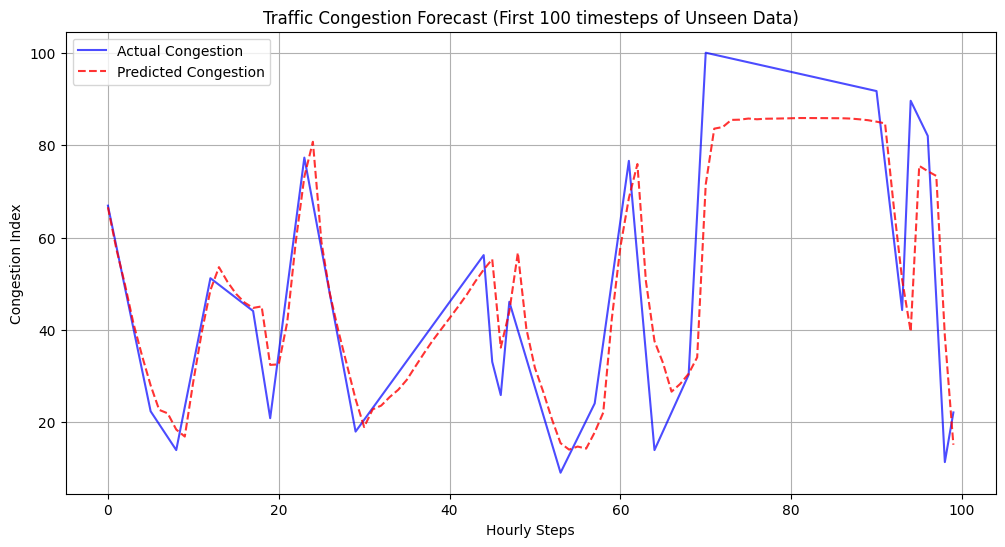

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout


print("Loading dataset...")
df = pd.read_csv('/content/Emergency dispatch traffic physics.csv')


df_sample = df.sample(n=10000, random_state=42).copy()


if 'Timestamp' in df_sample.columns:
    df_sample['Timestamp'] = pd.to_datetime(df_sample['Timestamp'])
else:

    time_col = [c for c in df_sample.columns if 'time' in c.lower()]
    if time_col:
        df_sample['Timestamp'] = pd.to_datetime(df_sample[time_col[0]])
    else:
        df_sample['Timestamp'] = pd.date_range(start='2023-01-01', periods=len(df_sample), freq='T')


for col in df_sample.columns:
    if df_sample[col].isnull().any():
        if df_sample[col].dtype in ['int64', 'float64']:
            df_sample[col] = df_sample[col].fillna(df_sample[col].median())
        else:
            df_sample[col] = df_sample[col].fillna(df_sample[col].mode()[0])

categorical_cols = df_sample.select_dtypes(include=['object']).columns
for col in categorical_cols:
    if col != 'Timestamp':
        le = LabelEncoder()
        df_sample[col] = le.fit_transform(df_sample[col].astype(str))


df_sample = df_sample.sort_values('Timestamp')


target_col = [c for c in df_sample.columns if 'congestion' in c.lower() or 'traffic' in c.lower()]
target_name = target_col[0] if target_col else df_sample.select_dtypes(include=[np.number]).columns[-1]


df_sample.set_index('Timestamp', inplace=True)
hourly_data = df_sample.resample('H').mean(numeric_only=True).interpolate(method='linear')


scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(hourly_data)


def create_sequences(data, target_idx, seq_length=12):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length, :])
        y.append(data[i+seq_length, target_idx])
    return np.array(X), np.array(y)

target_index = hourly_data.columns.get_loc(target_name)
seq_length = 6  # 6-hour sequence history
X, y = create_sequences(scaled_data, target_index, seq_length)

split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]


model = Sequential([
    LSTM(50, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=False),
    Dropout(0.2),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')
print("Training the LSTM model...")
history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.1, verbose=1)

predictions_scaled = model.predict(X_test)

dummy_pred = np.zeros((len(predictions_scaled), scaled_data.shape[1]))
dummy_pred[:, target_index] = predictions_scaled.flatten()
predictions = scaler.inverse_transform(dummy_pred)[:, target_index]

dummy_actual = np.zeros((len(y_test), scaled_data.shape[1]))
dummy_actual[:, target_index] = y_test
actuals = scaler.inverse_transform(dummy_actual)[:, target_index]

mae = mean_absolute_error(actuals, predictions)
rmse = np.sqrt(mean_squared_error(actuals, predictions))
print(f"\nEvaluation Metrics On Unseen Data:")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

plt.figure(figsize=(12, 6))
plt.plot(actuals[:100], label='Actual Congestion', color='blue', alpha=0.7)
plt.plot(predictions[:100], label='Predicted Congestion', color='red', linestyle='dashed', alpha=0.8)
plt.title('Traffic Congestion Forecast (First 100 timesteps of Unseen Data)')
plt.xlabel('Hourly Steps')
plt.ylabel('Congestion Index')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
https://colab.research.google.com/drive/1Y5Y2um0RPTrZxey9QDCMiGxF7u_TZbr-?usp=sharing